# Group 5's EDA Notebook


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

# Suppress warnings.
warnings.filterwarnings("ignore")
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

# All generated files go in this runtime's output folder.
output_folder = Path("eda_outputs")
output_folder.mkdir(exist_ok=True)


## Load the data



In [3]:
filename = "hmda_loan_data.csv"

assert Path(filename).exists(), "Upload the original CSV named hmda_loan_data.csv."
hmda = pd.read_csv(filename, dtype=str, keep_default_na=False)

# Stop here if an incomplete or different CSV was uploaded. sometimes upload would corrupt so i added this check
assert hmda.shape == (40734, 99), "Expected 40,734 rows and 99 columns. Recheck the uploaded CSV."
assert "activity_year" in hmda.columns, "The CSV is missing its original header."
hmda_original = hmda.copy()
hmda.head()


,activity_year,lei,derived_msa-md,state_code,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,...,denial_reason-2,denial_reason-3,denial_reason-4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,2025,7H6GLXDRUGQFU57RNE97,35614,NY,36079,36079010201,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,4312,24.93,107700,155,1518,1534,35
1,2025,7H6GLXDRUGQFU57RNE97,35614,NY,36047,36047117400,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,4331,97.62,107700,56,219,1504,0
2,2025,7H6GLXDRUGQFU57RNE97,35614,NY,36081,36081066402,C,VA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,3942,96.25,107700,119,730,1017,63
3,2025,7H6GLXDRUGQFU57RNE97,35004,NY,36103,36103147201,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,3714,42.86,164900,125,820,972,51
4,2025,7H6GLXDRUGQFU57RNE97,15380,NY,36063,36063021200,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,2310,58.05,101000,72,457,1358,0


In [4]:
print("Rows:", len(hmda))
print("Columns:", len(hmda.columns))
print("Years:", hmda["activity_year"].unique())
print("States:", hmda["state_code"].unique())
print("Exact duplicate rows:", hmda.duplicated().sum())
hmda["action_taken"].value_counts().sort_index()


Rows: 40734
Columns: 99
Years: ['2025']
States: ['NY']
Exact duplicate rows: 25


,count
action_taken,
1,15793
2,365
3,6070
4,4076
5,3599
6,10831


## Select the records we want
The three actions that we retain are action 1 (originated), action 2 (approved, but not accepted) and action 3 (denied). Purchased loan decisions made elsewhere are thus excluded, as well as both the withdrawal of and/or an applicant's failure to complete their application process do not produce either an approval or denial in this system for those applicants.

Additionally, we retain all home purchase transactions with at least one first-lien, a primary residence and a single-family residential dwelling consisting of one-to-four units. As such, business-loan and open end credit are excluded from our data. Therefore, while retaining a larger and more comparable sample than would be possible otherwise, our results will only reflect decision-making on a subset of loan applications.


In [5]:
# Reset first so rerunning this cell gives the same counts.
hmda = hmda_original.copy()
filters = [
    ("action_taken", ["1", "2", "3"]),
    ("loan_purpose", ["1"]),
    ("lien_status", ["1"]),
    ("occupancy_type", ["1"]),
    ("derived_dwelling_category", ["Single Family (1-4 Units):Site-Built"]),
    ("business_or_commercial_purpose", ["2"]),
    ("open-end_line_of_credit", ["2"]),
]

for column, values in filters:
    hmda = hmda.loc[hmda[column].isin(values)].copy()



## Prepare the variables
I retain all of the fields that we will be using and then convert any numeric fields to appropriate numeric types. Blank, NA (Not Available) and exempted values are treated as missing in each of the relevant fields. I also retain missing demographic information and unusual income information from the sample.

Denial is coded as a 1 for Action 3 and a 0 for Actions 1 and/or 2. Denial as measured here indicates what decision was made on the applicant's submitted application, however it does not indicate why an applicant was denied nor can it demonstrate discriminatory behavior.


In [6]:
numeric_columns = ["income", "loan_amount", "tract_minority_population_percent",
                   "tract_to_msa_income_percentage", "tract_population"]
keep_columns = ["activity_year", "state_code", "lei", "action_taken",
                "derived_race", "derived_ethnicity", "applicant_age",
                "loan_type", "debt_to_income_ratio", "derived_msa-md",
                "county_code", "census_tract"] + numeric_columns
hmda = hmda[keep_columns].copy()

for column in numeric_columns:
    hmda[column] = hmda[column].replace({"": np.nan, "NA": np.nan,
                                       "Exempt": np.nan})
    hmda[column] = pd.to_numeric(hmda[column])

hmda["denied"] = (hmda["action_taken"] == "3").astype(int)
hmda["age_band"] = hmda["applicant_age"].replace({"8888": "Missing"})


DTI combines ranges with discrete values. The range of 36 through 49 is a single band that preserves the original value in the column. Bands are created for missing values (DTI & Age) as well as five tract minority share bands. Tract Composition refers to the neighborhood characteristics of the property. It does not refer to the identity of the applicant.

In [7]:
hmda["dti_band"] = hmda["debt_to_income_ratio"].replace(
    {"": "Missing", "NA": "Missing", "Exempt": "Missing"}
)
exact_dti = [str(value) for value in range(36, 50)]
hmda.loc[hmda["debt_to_income_ratio"].isin(exact_dti), "dti_band"] = "36%-49%"

# Use nonoverlapping intervals
tract_labels = ["0–<20%", "20–<40%", "40–<60%", "60–<80%", "80–100%"]
hmda["tract_minority_band"] = pd.cut(
    hmda["tract_minority_population_percent"],
    bins=[0, 20, 40, 60, 80, np.inf], labels=tract_labels, right=False
).astype("string").fillna("Missing")

hmda.to_csv(output_folder / "hmda_2025_ny_cleaned.csv", index=False)
hmda.head()


,activity_year,state_code,lei,action_taken,derived_race,derived_ethnicity,applicant_age,loan_type,debt_to_income_ratio,derived_msa-md,...,census_tract,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population,denied,age_band,dti_band,tract_minority_band
111,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,35-44,1,30%-<36%,28740,...,36111952100,247.0,585000,52.21,68,3687,0,35-44,30%-<36%,40–<60%
112,2025,NY,7H6GLXDRUGQFU57RNE97,1,Joint,Not Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081026902,100.0,305000,95.74,61,4244,0,35-44,30%-<36%,80–100%
113,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,25-34,1,30%-<36%,35614,...,36119014701,125.0,225000,42.27,122,4977,0,25-34,30%-<36%,40–<60%
114,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Ethnicity Not Available,35-44,1,39,35614,...,36081092800,245.0,605000,9.14,181,3204,0,35-44,36%-49%,0–<20%
115,2025,NY,7H6GLXDRUGQFU57RNE97,2,White,Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081071304,100.0,85000,46.01,125,6386,0,35-44,30%-<36%,40–<60%


**Income** is in thousands of dollars, so 173 means $173,000. There are 395 missing incomes and 74 nonpositive values.


In [8]:
print("Applications:", len(hmda))
print("Denied:", hmda["denied"].sum())
print("Missing income:", hmda["income"].isna().sum())
print("Nonpositive income:", (hmda["income"] <= 0).sum())
print("Missing DTI:", (hmda["dti_band"] == "Missing").sum())
hmda["income"].describe()


Applications: 10513
Denied: 1476
Missing income: 395
Nonpositive income: 74
Missing DTI: 23


,income
count,10118.000000
mean,290.685709
std,483.276447
min,-719.000000
25%,106.000000
50%,173.000000
75%,317.000000
max,16328.000000


## Income distribution
A log scale is used here because many of the largest incomes were too big to be shown with a linear scale, making it difficult to see what the smaller incomes look like. This trick may have been discussed in CMPU250, but if not it's a method learned from CMPU366 - NLP. Only the 10,044 positive reported incomes are included for this plot. The 469 missing or non-positive values are still retained as part of the cleaned data.

Alt Text: Logarithmic histogram of annual income (in thousands), only including positive values. Black bars outline blue bars and add black diagonal hatching to allow bar identification in grayscale.

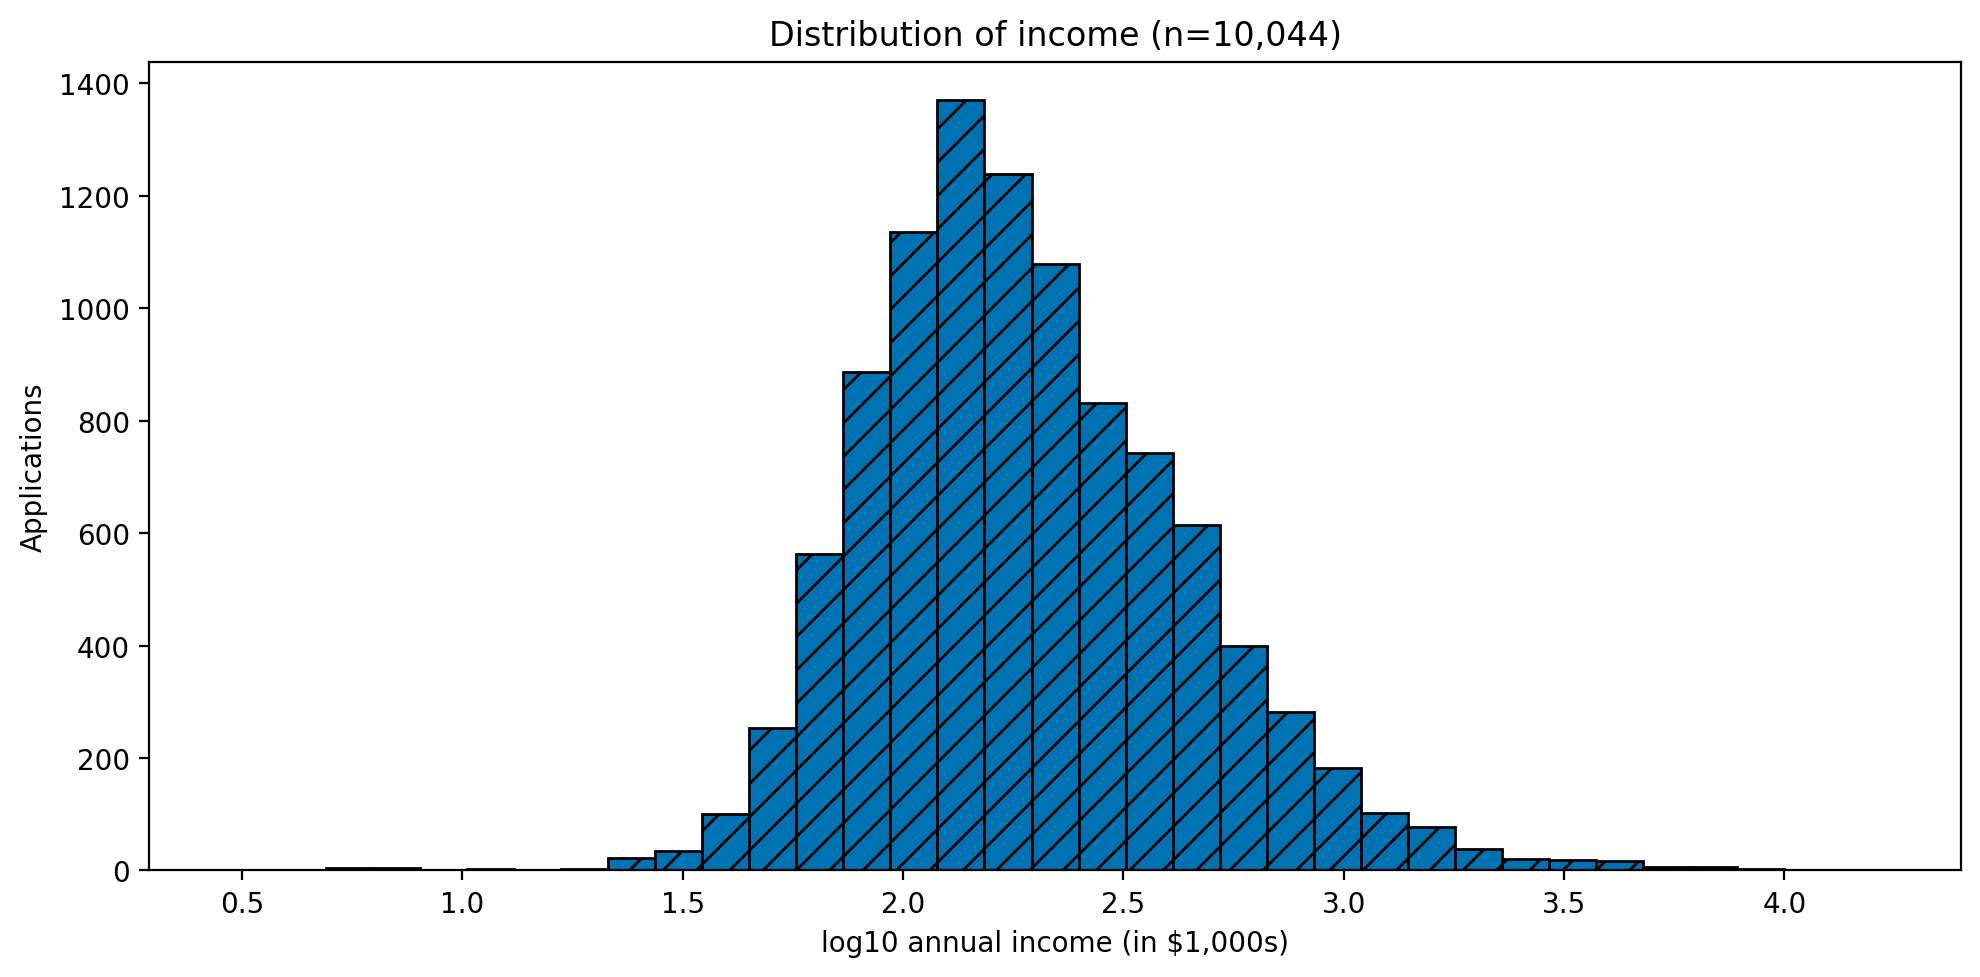

In [9]:
positive_income = hmda.loc[hmda["income"] > 0, "income"]
log_income = np.log10(positive_income)

ax = log_income.plot.hist(bins=35, figsize=(10, 5), color="#0072B2",
                          edgecolor="black", hatch="//")
ax.set_title(f"Distribution of income (n={len(positive_income):,})")
ax.set_xlabel("log10 annual income (in $1,000s)")
ax.set_ylabel("Applications")
plt.tight_layout()
plt.savefig(output_folder / "income_distribution.png", dpi=200,
            bbox_inches="tight")
plt.show()


The reported incomes have a long right tail: the median is roughly $173,000.

The mean is roughly $291,000.

## Save the results
This cell is for saving the results. change the bool to True to save/download to your computer a zip.

In [11]:
# Change to True when you want to download the results.
download_results = False

if download_results:
    import shutil
    from google.colab import files

    archive = shutil.make_archive("eda_results", "zip", output_folder)
    files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>